# Atividade de Nivelamento - LACEDA
## Integrante: Daniel de Oliveira

In [136]:
# Importação das bibliotecas + definição dos dataframes

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

dadosDep = pd.read_csv('dados/departamentos.csv')
dadosFiliais = pd.read_csv('dados/filiais.csv')
dadosFuncionarios = pd.read_csv('dados/funcionarios.csv')
dadosUnificados = pd.read_csv('dados/dados_unificados.csv')

In [137]:
# Tratamento da base de dados de funcionários (que possui 'erros')

dadosFuncionarios["nome"] = dadosFuncionarios["nome"].str.replace(r"[0-9]", "", regex=True)
dadosFuncionarios["genero"] = dadosFuncionarios["genero"].replace({"Fem": "Feminino"})
dadosFuncionarios["salario_base"] = dadosFuncionarios["salario_base"].replace("[^0-9.,]", "", regex=True)
dadosFuncionarios["salario_base"] = dadosFuncionarios["salario_base"].str.replace(".", ",", regex=False)
dadosFuncionarios["data_promocao"] = pd.to_datetime(dadosFuncionarios["data_promocao"], format = "mixed", errors='coerce')
dadosFuncionarios["data_admissao"] = pd.to_datetime(dadosFuncionarios["data_admissao"], format = "mixed", errors='coerce')

In [138]:
# Criação do dataframe unificado para análise

dadosUnificados = pd.merge(dadosFuncionarios, dadosDep, on='id_departamento', how='left')
dadosUnificados = pd.merge(dadosUnificados, dadosFiliais, on='id_filial', how='left')

In [ ]:
# Criação de flags para evaluation
dadosUnificados['i  nativo'] = (dadosUnificados['status_atual'] == 'Desligado').astype(int)
dadosUnificados['home_office'] = dadosUnificados['home_office'].replace({True: 'Remoto', False: 'Presencial'})
dadosUnificados['faixa_horas_extras'] = pd.cut(dadosUnificados['horas_extras_mes'], bins=[-1, 10, 20, 30, 40, np.inf], labels=['0-10', '11-20', '21-30', '31-40', '41+'])
bins = np.arange(1, 5.5, 0.5)
labels = ["1.0–1.5", "1.5–2.0", "2.0–2.5", "2.5–3.0", "3.0–3.5", "3.5–4.0", "4.0–4.5", "4.5–5.0"]
dadosUnificados["faixa_satisfacao"] = pd.cut(dadosUnificados["score_satisfacao"], bins=bins, labels=labels, include_lowest=True)

# CSV para visualização
dadosUnificados.to_csv('dados/dados_unificados.csv', index=False)

# Dados para análise

estadoData = dadosUnificados.groupby('estado', as_index=False)['inativo'].mean()
estadoData['inativo'] *= 100
estadoData = estadoData.sort_values('inativo', ascending=False)

generoData = dadosUnificados.groupby('genero', as_index=False)['inativo'].mean()
generoData['inativo'] *= 100
generoData = generoData.sort_values('inativo', ascending=False)

dptoData = dadosUnificados.groupby('nome_departamento', as_index=False)['inativo'].mean()
dptoData['inativo'] *= 100
dptoData = dptoData.sort_values('inativo', ascending=False)

nivelData = dadosUnificados.groupby('nivel', as_index=False)['inativo'].mean()
nivelData['inativo'] *= 100
nivelData = nivelData.sort_values('inativo', ascending=False)

extrasData = dadosUnificados.groupby('faixa_horas_extras', as_index=False)['inativo'].mean()
extrasData['inativo'] *= 100
extrasData = extrasData.sort_values('inativo', ascending=False)

homeData = dadosUnificados.groupby('home_office', as_index=False)['inativo'].mean()
homeData['inativo'] *= 100
homeData = homeData.sort_values('inativo', ascending=False)

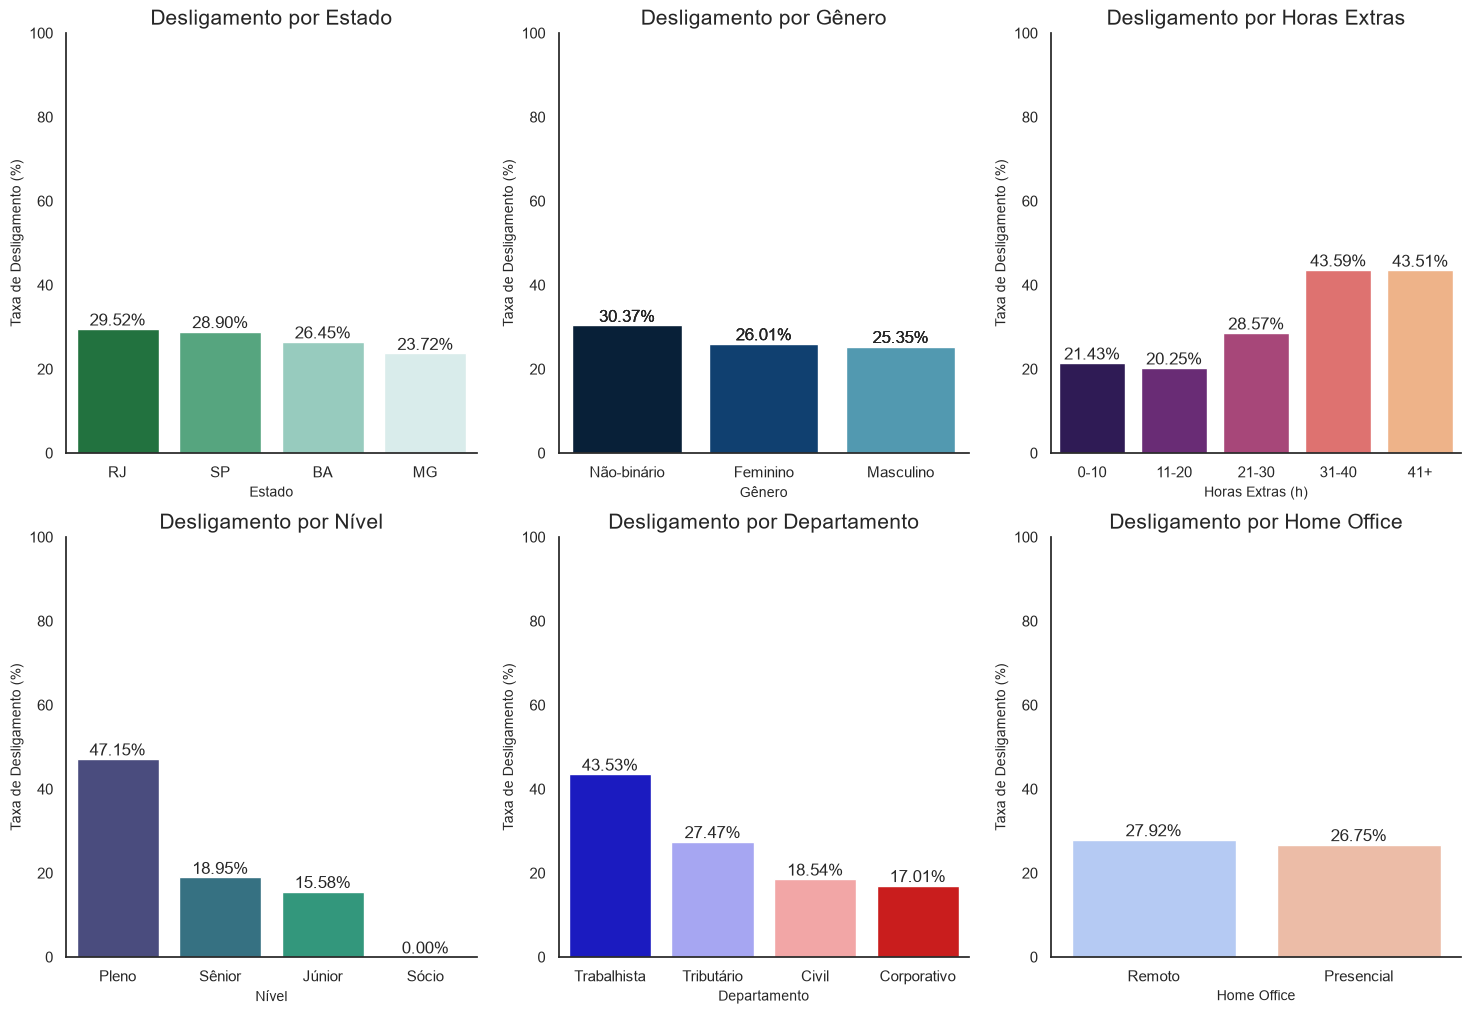

In [ ]:
# Criação dos Gráficos

sns.set_theme(style="white")
tab, eixos = plt.subplots(2, 3, figsize=(18, 12))
eixosEstado = eixos[0, 0]
sns.barplot(data=estadoData, x='estado', y='inativo', ax=eixos[0, 0], palette='BuGn_r', hue = 'estado')
eixosEstado.set_title('Desligamento por Estado', fontsize=15)
eixosEstado.set_xlabel('Estado', fontsize=10)
eixosEstado.set_ylabel('Taxa de Desligamento (%)', fontsize=10)
eixosEstado.set_ylim(0, 100)
for i in eixosEstado.containers:
    eixosEstado.bar_label(i, fmt='%.2f%%', fontsize=12)

eixosGenero = eixos[0, 1]
sns.barplot(data=generoData, x='genero', y='inativo', ax=eixos[0, 1], palette='ocean', hue = 'genero')
eixosGenero.set_title('Desligamento por Gênero', fontsize=15)
eixosGenero.set_xlabel('Gênero', fontsize=10)
eixosGenero.set_ylabel('Taxa de Desligamento (%)', fontsize=10)
eixosGenero.set_ylim(0, 100)
for i in eixosGenero.containers:
    eixosGenero.bar_label(i, fmt='%.2f%%', fontsize=12)
    
eixosGenero = eixos[0, 1]
sns.barplot(data=generoData, x='genero', y='inativo', ax=eixos[0, 1], palette='ocean', hue = 'genero')
eixosGenero.set_title('Desligamento por Gênero', fontsize=15)
eixosGenero.set_xlabel('Gênero', fontsize=10)
eixosGenero.set_ylabel('Taxa de Desligamento (%)', fontsize=10)
eixosGenero.set_ylim(0, 100)
for i in eixosGenero.containers:
    eixosGenero.bar_label(i, fmt='%.2f%%', fontsize=12)
    
eixosNivel = eixos[1, 0]
sns.barplot(data=nivelData, x='nivel', y='inativo', ax=eixos[1, 0], palette='viridis', hue = 'nivel')
eixosNivel.set_title('Desligamento por Nível', fontsize=15)
eixosNivel.set_xlabel('Nível', fontsize=10)
eixosNivel.set_ylabel('Taxa de Desligamento (%)', fontsize=10)
eixosNivel.set_ylim(0, 100)
for i in eixosNivel.containers:
    eixosNivel.bar_label(i, fmt='%.2f%%', fontsize=12) 
    
eixosDep = eixos[1, 1]
sns.barplot(data=dptoData, x='nome_departamento', y='inativo', ax=eixos[1, 1], palette='seismic', hue = 'nome_departamento')
eixosDep.set_title('Desligamento por Departamento', fontsize=15)
eixosDep.set_xlabel('Departamento', fontsize=10)
eixosDep.set_ylabel('Taxa de Desligamento (%)', fontsize=10)
eixosDep.set_ylim(0, 100)
for i in eixosDep.containers:
    eixosDep.bar_label(i, fmt='%.2f%%', fontsize=12)
eixosHome = eixos[1, 2]
sns.barplot(data=homeData, x='home_office', y='inativo', ax=eixos[1, 2], palette='coolwarm', hue = 'home_office')
eixosHome.set_title('Desligamento por Home Office', fontsize=15)
eixosHome.set_xlabel('Home Office', fontsize=10)
eixosHome.set_ylabel('Taxa de Desligamento (%)', fontsize=10)
eixosHome.set_ylim(0, 100)
for i in eixosHome.containers:
    eixosHome.bar_label(i, fmt='%.2f%%', fontsize=12)
    
eixosExtras = eixos[0, 2]
sns.barplot(data=extrasData, x='faixa_horas_extras', y='inativo', ax=eixos[0, 2], palette='magma', hue = 'faixa_horas_extras', dodge=False)
eixosExtras.set_title('Desligamento por Horas Extras', fontsize=15)
eixosExtras.set_xlabel('Horas Extras (h)', fontsize=10)
eixosExtras.set_ylabel('Taxa de Desligamento (%)', fontsize=10)
eixosExtras.set_ylim(0, 100)
for i in eixosExtras.containers:
    eixosExtras.bar_label(i, fmt='%.2f%%', fontsize=12)
sns.despine()

In [ ]:
# Criação da Tabela
evasaoTrabalho = ((dadosUnificados.groupby(['faixa_satisfacao', 'nivel'])['inativo'].mean() * 100).round(2).unstack(fill_value=0))
evasaoTrabalho.index.name = None
evasaoTrabalho.columns.name = "Faixa de Satisfação"
display(evasaoTrabalho.style.format("{:.2f}%"))

Faixa de Satisfação,Júnior,Pleno,Sênior,Sócio
1.0–1.5,54.17%,60.00%,8.33%,0.00%
1.5–2.0,54.17%,44.00%,0.00%,0.00%
2.0–2.5,60.00%,0.00%,50.00%,0.00%
2.5–3.0,0.00%,100.00%,0.00%,0.00%
3.0–3.5,0.00%,42.11%,50.00%,0.00%
3.5–4.0,0.00%,42.86%,14.29%,0.00%
4.0–4.5,0.00%,30.95%,13.64%,0.00%
4.5–5.0,0.00%,69.70%,9.09%,0.00%
